In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [121]:

# Temperatures and pressure
Tb = 4501
Tm = 1789
T01 = 244
T02 = 943
P0 = 101325

# Enthalpies, kJ/mol
delH_v = 121
delH_f = 65.3
delH_ag = 91.1
delH_ba = -41.7
delH_ab = 41.7

# Atomic weight and densities
AW_vib = 45.3  # g/mol

rho_alpha = 5.45       # g/cm^3
rho_beta = 5.50
rho_gamma = 4.99
rho_liquid = 4.28

# Molar volumes, cm^3/mol

#The molar densities need to be converted into molar volumes. 
V_a = AW_vib / rho_alpha
V_b = AW_vib / rho_beta
V_g = AW_vib / rho_gamma
V_l = AW_vib / rho_liquid

# Volume changes
delV_ab = V_b - V_a
delV_bg = V_g - V_b
delV_gl = V_l - V_g

# Gas constant
R = 8.314e-3  # kJ/mol K

# Hess's law
delH_bg = delH_ag - delH_ba
delH_gv = delH_f + delH_v
delH_bv = delH_bg + delH_gv
delH_av = delH_ba + delH_bv

γ-L-V triple point
T = 1789 K
P = 753.2523165274141 Pa

β-γ-V triple point
T = 943 K
P = 0.009925778457027785 Pa

α-β-V triple point
T = 244 K
P = 2.284232872152708e-53 Pa


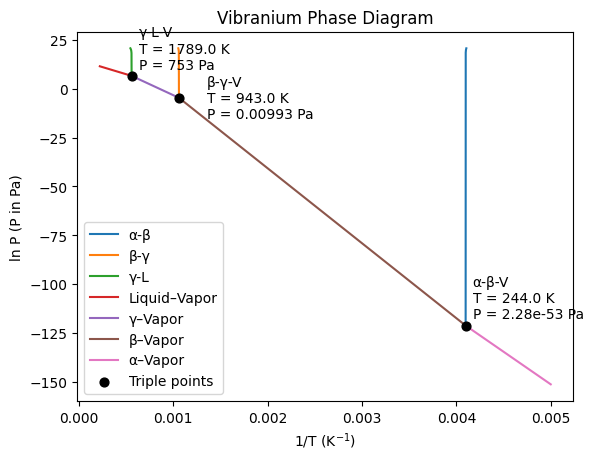

In [124]:


# -------------------------
# Temperature arrays
# -------------------------

T_lv = np.linspace(Tm, Tb, 500)
T_gv = np.linspace(T02, Tm, 500)
T_bv = np.linspace(T01, T02, 500)
T_av = np.linspace(200, T01, 500)

# -------------------------
#Boundary Curves
# condensed boundaries: T(P) = T0*exp((P-P0)*dV/dH), from triple point up to 1 GPa

# Pressure ranges from triple point to 1 GPa
P_ab = np.exp(np.linspace(lnP_tp_ab, np.log(1e9), 200))
P_bg = np.exp(np.linspace(lnP_tp_bg, np.log(1e9), 200))
P_gl = np.exp(np.linspace(lnP_tp_gl, np.log(1e9), 200))

# α-β boundary
T_ab = T_tp_ab * np.exp(
    (P_ab - np.exp(lnP_tp_ab)) * delV_ab * 1e-6 / (delH_ab * 1000)
)

# β-γ boundary
T_bg = T_tp_bg * np.exp(
    (P_bg - np.exp(lnP_tp_bg)) * delV_bg * 1e-6 / (delH_bg * 1000)
)

# γ-liquid boundary
T_gl = T_tp_gl * np.exp(
    (P_gl - np.exp(lnP_tp_gl)) * delV_gl * 1e-6 / (delH_f * 1000)    #
)

# Convert pressure to ln(P)
lnP_ab = np.log(P_ab)
lnP_bg = np.log(P_bg)
lnP_gl = np.log(P_gl)

# -------------------------
# Plot
# -------------------------

plt.plot(1/T_ab, lnP_ab, label='α-β')
plt.plot(1/T_bg, lnP_bg, label='β-γ')
plt.plot(1/T_gl, lnP_gl, label='γ-L')

#Vapor boundaries
#for vapor boundaries we make the approximation that del V ≈ V_vapor

# Liquid-vapor curve

lnP_lv = np.log(P0) - (delH_v / R) * (1/T_lv - 1/Tb)  

# γ-L-V triple point
lnP_tp_gl = lnP_lv[0]

# -------------------------
# γ-vapor curve

lnP_gv = lnP_tp_gl - (delH_gv / R) * (1/T_gv - 1/Tm)

# β-γ-V triple point
lnP_tp_bg = lnP_gv[0]

# -------------------------
# β-vapor curve

lnP_bv = lnP_tp_bg - (delH_bv / R) * (1/T_bv - 1/T02)

# α-β-V triple point
lnP_tp_ab = lnP_bv[0]


# α-vapor curve

lnP_av = lnP_tp_ab - (delH_av / R) * (1/T_av - 1/T01)




print("γ-L-V triple point")
print("T =", Tm, "K")
print("P =", np.exp(lnP_tp_gl), "Pa")
print()

print("β-γ-V triple point")
print("T =", T02, "K")
print("P =", np.exp(lnP_tp_bg), "Pa")
print()

print("α-β-V triple point")
print("T =", T01, "K")
print("P =", np.exp(lnP_tp_ab), "Pa")


plt.plot(1/T_lv, lnP_lv, label='Liquid–Vapor')
plt.plot(1/T_gv, lnP_gv, label='γ–Vapor')
plt.plot(1/T_bv,  lnP_bv, label='β–Vapor')
plt.plot(1/T_av, lnP_av, label='α–Vapor')


plt.scatter(
    [1/T_tp_gl, 1/T_tp_bg, 1/T_tp_ab],
    [lnP_tp_gl, lnP_tp_bg, lnP_tp_ab],
    color='black',
    s=40,
    zorder=5,
    label='Triple points'
)


# Triple-point labels
plt.annotate(
    f'γ-L-V\nT = {T_tp_gl:.1f} K\nP = {np.exp(lnP_tp_gl):.3g} Pa',
    (1/T_tp_gl, lnP_tp_gl),
    xytext=(5, 5),
    textcoords='offset points'
)

plt.annotate(
    f'β-γ-V\nT = {T_tp_bg:.1f} K\nP = {np.exp(lnP_tp_bg):.3g} Pa',
    (1/T_tp_bg, lnP_tp_bg),
    xytext=(20,-15),
    textcoords='offset points'
)

plt.annotate(
    f'α-β-V\nT = {T_tp_ab:.1f} K\nP = {np.exp(lnP_tp_ab):.3g} Pa',
    (1/T_tp_ab, lnP_tp_ab),
    xytext=(5, 5),
    textcoords='offset points'
)

plt.title("Vibranium Phase Diagram")
plt.xlabel("1/T (K$^{-1})$")
plt.ylabel("ln P (P in Pa)")
plt.legend()


For Part B we want to find the  α-vibranium → γ-vibranium transformation
Predict the temperature at which α-vibranium was observed to transform to γ phase
During Dr. MacLain’s original experiments

In [127]:
delS_ab=delH_ab/T01
delS_bg=delH_bg/T02
delS_ag=delS_ab+delS_bg

#Known G= H-TDelS
#to find G_ag = H_{ag}-T{ag}DelS{ag},
#Rearrange the equation and solve for T
#T_{ag}=-G_{ag}+H_{ag}/(delS_{ag})
#We also know at the transition that G_{ag} =0 making the equation
#T_{ag}=H_{ag}/delS_{ag}

0.3117287867461711
292.2412169594695


Known G= H-TDelS
to find G_ag = H_{ag}-T{ag}DelS{ag},

Rearrange the equation and solve for T

T_{ag}=-G_{ag}+H_{ag}/(delS_{ag})

We also know at the transition that G_{ag} =0 making the equation

T_{ag}=H_{ag}/delS_{ag}

In [128]:
T= delH_ag/delS_ag

print(T)

292.2412169594695


We find the temperature at which  α-vibranium was observed to transform to γ phase was at 292 K.